In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

print("Libraries loaded successfully")

Libraries loaded successfully


Load processed data

In [2]:
PROCESSED_PATH = "../data/processed/"

customers = pd.read_csv(f"{PROCESSED_PATH}customers_clean.csv")
orders = pd.read_csv(f"{PROCESSED_PATH}orders_analytics.csv")
order_items = pd.read_csv(f"{PROCESSED_PATH}order_items_clean.csv")
payments = pd.read_csv(f"{PROCESSED_PATH}payments_clean.csv")
reviews = pd.read_csv(f"{PROCESSED_PATH}reviews_clean.csv")
products = pd.read_csv(f"{PROCESSED_PATH}products_clean.csv")
sellers = pd.read_csv(f"{PROCESSED_PATH}sellers_clean.csv")

print("All datasets loaded successfully")

All datasets loaded successfully


Convert dates

In [3]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

print("Date columns converted")

Date columns converted


Basic dataset overview

In [4]:
datasets = {
    "customers": customers,
    "orders": orders,
    "order_items": order_items,
    "payments": payments,
    "reviews": reviews,
    "products": products,
    "sellers": sellers
}

for name, df in datasets.items():
    print(f"{name:15} → {df.shape}")

customers       → (99441, 5)
orders          → (99441, 22)
order_items     → (112650, 7)
payments        → (103886, 5)
reviews         → (99224, 7)
products        → (32951, 11)
sellers         → (3095, 4)


Business KPI summary

In [5]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
]

total_orders = len(delivered_orders)

total_revenue = delivered_orders["total_order_value"].sum()

total_customers = customers["customer_unique_id"].nunique()

average_order_value = delivered_orders["total_order_value"].mean()

average_delivery_days = delivered_orders["delivery_days"].mean()

late_orders = delivered_orders["is_late"].sum()

late_percentage = (
    late_orders / total_orders * 100
)

print("========== BUSINESS KPIs ==========")
print(f"Total Orders          : {total_orders:,}")
print(f"Total Customers       : {total_customers:,}")
print(f"Total Revenue         : {total_revenue:,.2f}")
print(f"Average Order Value   : {average_order_value:,.2f}")
print(f"Avg Delivery Days     : {average_delivery_days:.2f}")
print(f"Late Orders           : {late_orders:,}")
print(f"Late Order %          : {late_percentage:.2f}%")

========== BUSINESS KPIs ==========
Total Orders          : 96,478
Total Customers       : 96,096
Total Revenue         : 15,419,773.75
Average Order Value   : 159.83
Avg Delivery Days     : 12.56
Late Orders           : 7,826
Late Order %          : 8.11%


Monthly revenue trend

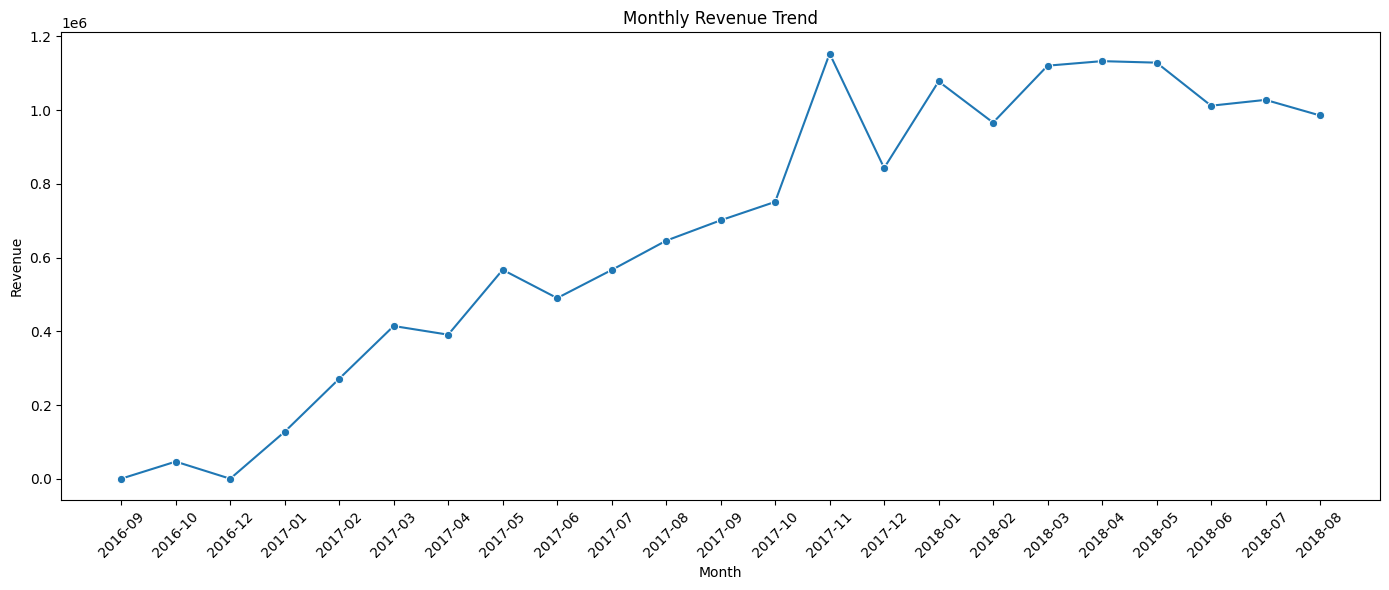

In [6]:
monthly_revenue = (
    delivered_orders
    .groupby(["order_year", "order_month"])
    ["total_order_value"]
    .sum()
    .reset_index()
)

monthly_revenue["month"] = (
    monthly_revenue["order_year"].astype(str)
    + "-"
    + monthly_revenue["order_month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_revenue,
    x="month",
    y="total_order_value",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top product categories

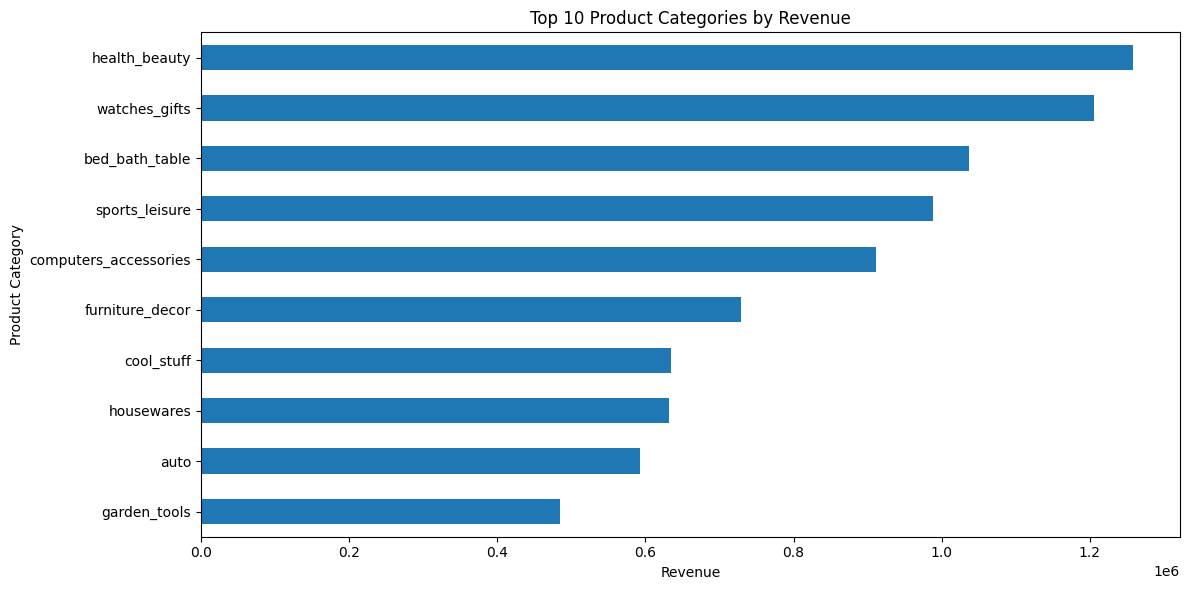

In [7]:
category_revenue = (
    order_items
    .merge(
        products[["product_id", "product_category"]],
        on="product_id",
        how="left"
    )
    .groupby("product_category")["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

category_revenue.sort_values().plot(kind="barh")

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

Customer state analysis

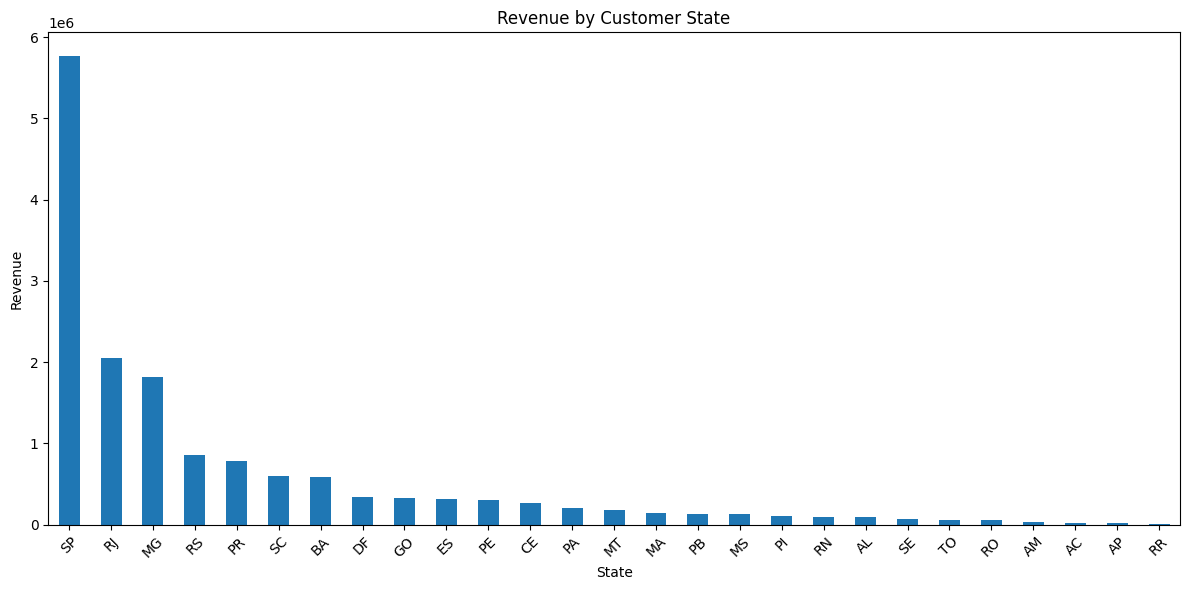

In [8]:
state_orders = (
    orders
    .merge(
        customers[["customer_id", "customer_state"]],
        on="customer_id",
        how="left"
    )
)

state_revenue = (
    state_orders[
        state_orders["order_status"] == "delivered"
    ]
    .groupby("customer_state")["total_order_value"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

state_revenue.plot(kind="bar")

plt.title("Revenue by Customer State")
plt.xlabel("State")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Review score distribution

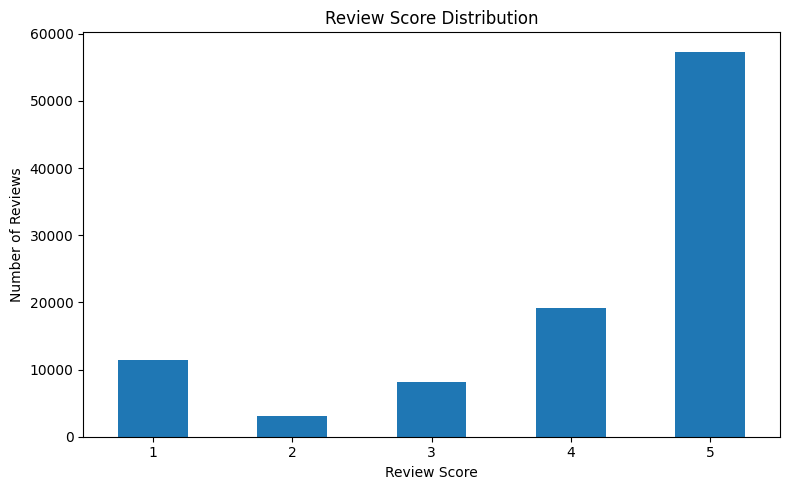

In [9]:
review_counts = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

review_counts.plot(kind="bar")

plt.title("Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Delivery performance

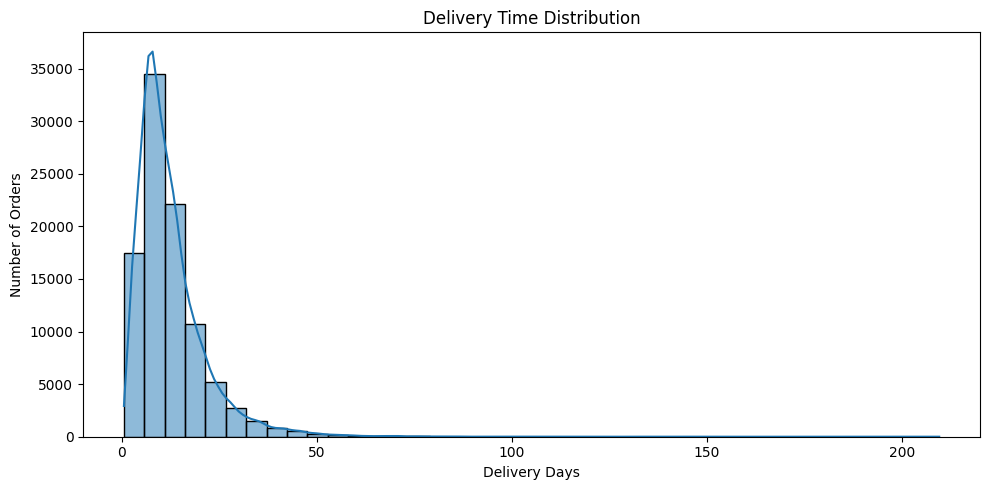

In [10]:
delivery_data = delivered_orders[
    delivered_orders["delivery_days"].notna()
]

plt.figure(figsize=(10, 5))

sns.histplot(
    delivery_data["delivery_days"],
    bins=40,
    kde=True
)

plt.title("Delivery Time Distribution")
plt.xlabel("Delivery Days")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

EDA

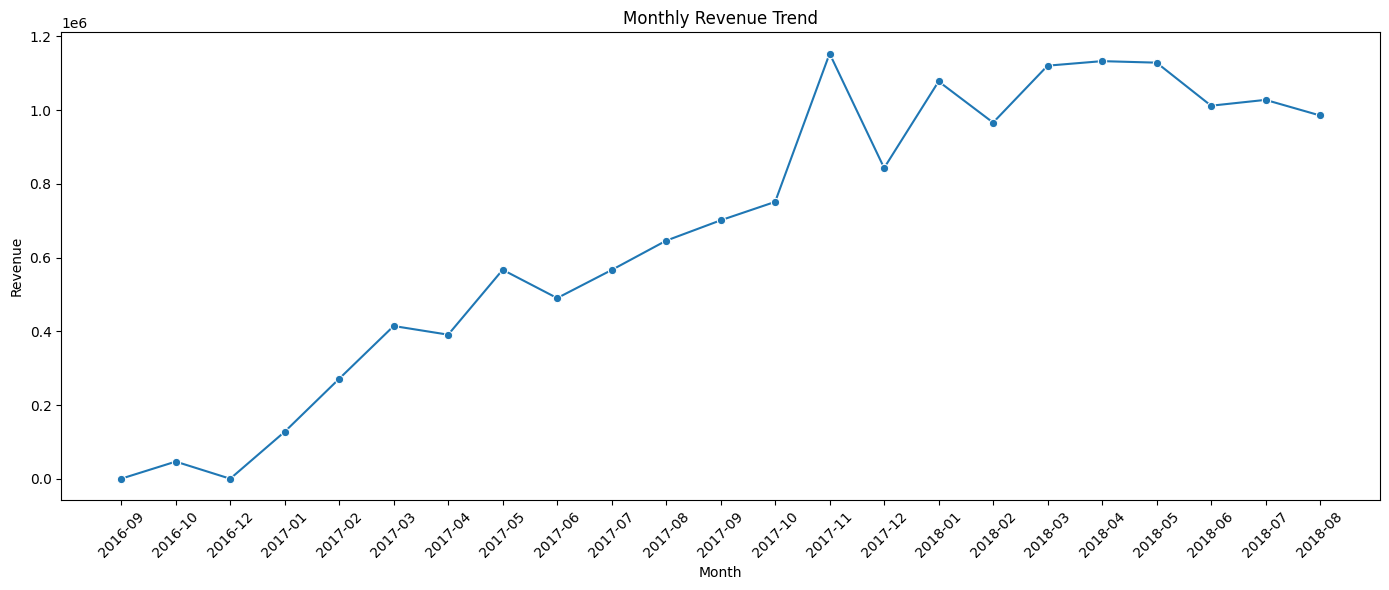

In [11]:
monthly_revenue = (
    delivered_orders
    .groupby(["order_year", "order_month"])
    ["total_order_value"]
    .sum()
    .reset_index()
)

monthly_revenue["month"] = (
    monthly_revenue["order_year"].astype(str)
    + "-"
    + monthly_revenue["order_month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_revenue,
    x="month",
    y="total_order_value",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Customer RFM Analysis

Customer Transactions
        ↓
       RFM
   ┌────┼────┐
   ↓    ↓    ↓
Recency Frequency Monetary
   └────┼────┘
        ↓
 Customer Segments
        ↓
Recommendations